# PTB-XL — Data loading and overview

In [2]:
import ast
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb

from sklearn.preprocessing import MultiLabelBinarizer

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

In [4]:
# loading data (initial)
# Project paths
PROJECT_ROOT = Path.cwd().resolve().parent
DATA_DIR = PROJECT_ROOT / "data" / "ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3"

METADATA_FILE = DATA_DIR / "ptbxl_database.csv"
SCP_FILE = DATA_DIR / "scp_statements.csv"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR:", DATA_DIR)
print("Metadata exists:", METADATA_FILE.exists())
print("SCP exists:", SCP_FILE.exists())

PROJECT_ROOT: C:\Users\Sherif\Desktop\ECG analysis
DATA_DIR: C:\Users\Sherif\Desktop\ECG analysis\data\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
Metadata exists: True
SCP exists: True


In [6]:
md = pd.read_csv(METADATA_FILE, index_col="ecg_id")
scp_df = pd.read_csv(SCP_FILE, index_col=0)

print("Metadata shape:", md.shape)
print("SCP statements shape:", scp_df.shape)

display(md.head())
display(scp_df.head())

Metadata shape: (21799, 27)
SCP statements shape: (71, 12)


,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,scp_codes,heart_axis,infarction_stadium1,infarction_stadium2,validated_by,second_opinion,initial_autogenerated_report,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
ecg_id,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",NaN,NaN,NaN,NaN,False,False,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,"{'NORM': 80.0, 'SBRAD': 0.0}",NaN,NaN,NaN,NaN,False,False,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,"{'NORM': 100.0, 'SR': 0.0}",NaN,NaN,NaN,NaN,False,False,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,sinusrhythmus normales ekg,"{'NORM': 100.0, 'SR': 0.0}",NaN,NaN,NaN,NaN,False,False,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,sinusrhythmus normales ekg,"{'NORM': 100.0, 'SR': 0.0}",NaN,NaN,NaN,NaN,False,False,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7


In [7]:
type(md["scp_codes"].iloc[0])

str

In [8]:
#parsing scp codes in metadata
df["scp_codes"] = df["scp_codes"].apply(ast.literal_eval)

print(type(df["scp_codes"].iloc[0]))
print(df["scp_codes"].iloc[0])

<class 'dict'>
{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}


In [9]:
print("Columns in ptbxl_database.csv:")
print(df.columns.tolist())

Columns in ptbxl_database.csv:
['patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']


In [ ]:
#missing values 
missing_ratio = df.isna().mean().sort_values(ascending=False) * 100
missing_df = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": missing_ratio
}).sort_values("missing_percent", ascending=False)

display(missing_df.head(20))

,missing_count,missing_percent
electrodes_problems,21769,99.862379
infarction_stadium2,21696,99.527501
pacemaker,21508,98.665076
burst_noise,21186,97.187944
baseline_drift,20201,92.669389
extra_beats,19850,91.059223
static_noise,18539,85.045186
infarction_stadium1,16187,74.255700
height,14825,68.007707
weight,12378,56.782421


In [11]:
n_ecgs = len(df)
n_patients = df["patient_id"].nunique()

print(f"Number of ECG records: {n_ecgs}")
print(f"Number of unique patients: {n_patients}")

ecgs_per_patient = df.groupby("patient_id").size()
print("\nECGs per patient:")
print(ecgs_per_patient.describe())

Number of ECG records: 21799
Number of unique patients: 18869

ECGs per patient:
count    18869.000000
mean         1.155281
std          0.523105
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         10.000000
dtype: float64


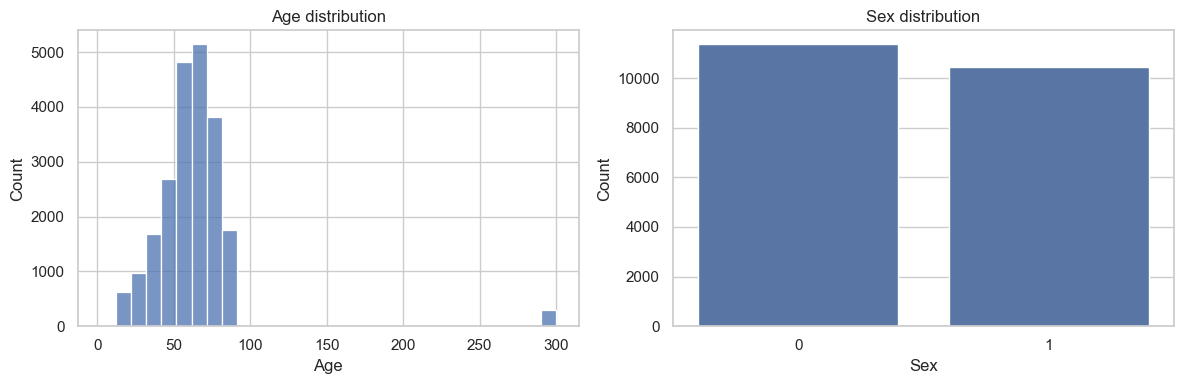

In [12]:
# age and sex explo
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["age"].dropna(), bins=30, ax=axes[0])
axes[0].set_title("Age distribution")
axes[0].set_xlabel("Age")

sex_counts = df["sex"].value_counts(dropna=False)
sns.barplot(x=sex_counts.index.astype(str), y=sex_counts.values, ax=axes[1])
axes[1].set_title("Sex distribution")
axes[1].set_xlabel("Sex")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

In [ ]:
print("strat_fold distribution:")
display(df["strat_fold"].value_counts().sort_index())

strat_fold distribution:


strat_fold
1     2175
2     2181
3     2192
4     2174
5     2174
6     2173
7     2176
8     2173
9     2183
10    2198
Name: count, dtype: int64

In [14]:
diagnostic_statements = scp_df[scp_df["diagnostic"] == 1].copy()

print("Number of diagnostic statements:", len(diagnostic_statements))
display(diagnostic_statements.head())

Number of diagnostic statements: 44


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7


In [15]:
def extract_diagnostic_superclasses(scp_codes_dict, diagnostic_df):
    classes = []
    for code in scp_codes_dict.keys():
        if code in diagnostic_df.index:
            diagnostic_class = diagnostic_df.loc[code, "diagnostic_class"]
            if pd.notna(diagnostic_class):
                classes.append(diagnostic_class)
    return sorted(list(set(classes)))

In [16]:
df["diagnostic_superclass"] = df["scp_codes"].apply(
    lambda x: extract_diagnostic_superclasses(x, diagnostic_statements)
)

display(df[["patient_id", "scp_codes", "diagnostic_superclass"]].head(10))

,patient_id,scp_codes,diagnostic_superclass
ecg_id,,,
1,15709.0,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",[NORM]
2,13243.0,"{'NORM': 80.0, 'SBRAD': 0.0}",[NORM]
3,20372.0,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
4,17014.0,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
5,17448.0,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
6,19005.0,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
7,16193.0,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
8,11275.0,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",[MI]
9,18792.0,"{'NORM': 100.0, 'SR': 0.0}",[NORM]


In [17]:
# checkng how many ecgs have diagnostic labels 
df["num_diagnostic_superclasses"] = df["diagnostic_superclass"].apply(len)

print(df["num_diagnostic_superclasses"].describe())

print("\nRecords with at least one diagnostic superclass:",
      (df["num_diagnostic_superclasses"] > 0).sum())

count    21799.000000
mean         1.273682
std          0.603352
min          0.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          4.000000
Name: num_diagnostic_superclasses, dtype: float64

Records with at least one diagnostic superclass: 21388


NORM    9514
MI      5469
STTC    5235
CD      4898
HYP     2649
dtype: int64

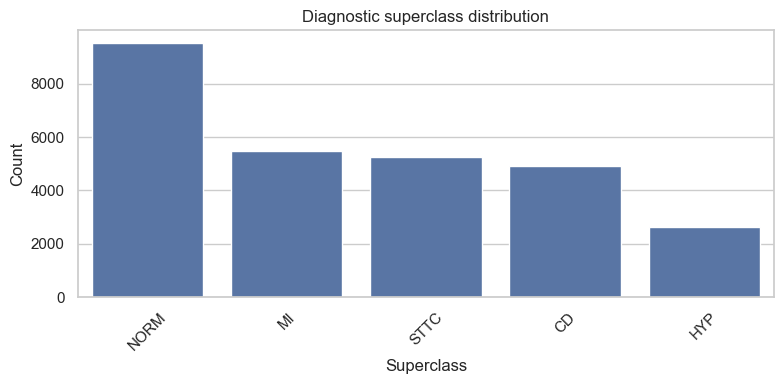

In [18]:
all_superclasses = [label for labels in df["diagnostic_superclass"] for label in labels]
superclass_counts = pd.Series(Counter(all_superclasses)).sort_values(ascending=False)

display(superclass_counts)

plt.figure(figsize=(8, 4))
sns.barplot(x=superclass_counts.index, y=superclass_counts.values)
plt.title("Diagnostic superclass distribution")
plt.xlabel("Superclass")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

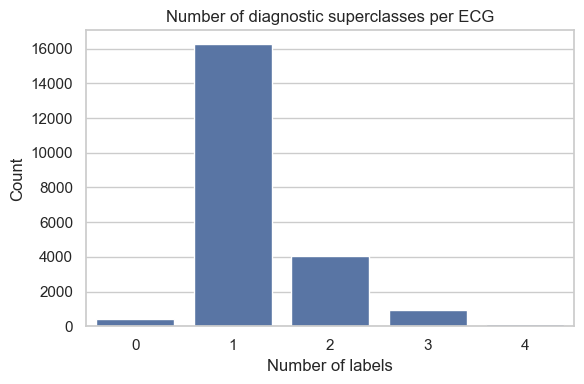

In [19]:
plt.figure(figsize=(6, 4))
sns.countplot(x=df["num_diagnostic_superclasses"])
plt.title("Number of diagnostic superclasses per ECG")
plt.xlabel("Number of labels")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [ ]:
# creating one hot classes for each ecg 
mlb = MultiLabelBinarizer()
Y_super = mlb.fit_transform(df["diagnostic_superclass"])

y_super_df = pd.DataFrame(
    Y_super,
    index=df.index,
    columns=mlb.classes_
)

display(y_super_df.head())
print("Superclass columns:", list(mlb.classes_))

,CD,HYP,MI,NORM,STTC
ecg_id,,,,,
1,0,0,0,1,0
2,0,0,0,1,0
3,0,0,0,1,0
4,0,0,0,1,0
5,0,0,0,1,0


Superclass columns: ['CD', 'HYP', 'MI', 'NORM', 'STTC']


In [21]:
df = pd.concat([df, y_super_df], axis=1)
display(df.head())

,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,scp_codes,heart_axis,infarction_stadium1,infarction_stadium2,validated_by,second_opinion,initial_autogenerated_report,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr,diagnostic_superclass,num_diagnostic_superclasses,CD,HYP,MI,NORM,STTC
ecg_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",NaN,NaN,NaN,NaN,False,False,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr,[NORM],1,0,0,0,1,0
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,"{'NORM': 80.0, 'SBRAD': 0.0}",NaN,NaN,NaN,NaN,False,False,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr,[NORM],1,0,0,0,1,0
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,"{'NORM': 100.0, 'SR': 0.0}",NaN,NaN,NaN,NaN,False,False,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr,[NORM],1,0,0,0,1,0
4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,sinusrhythmus normales ekg,"{'NORM': 100.0, 'SR': 0.0}",NaN,NaN,NaN,NaN,False,False,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr,[NORM],1,0,0,0,1,0
5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,sinusrhythmus normales ekg,"{'NORM': 100.0, 'SR': 0.0}",NaN,NaN,NaN,NaN,False,False,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr,[NORM],1,0,0,0,1,0


In [22]:
# Official physionet split reco
train_df = df[df["strat_fold"].between(1, 8)].copy()
val_df = df[df["strat_fold"] == 9].copy()
test_df = df[df["strat_fold"] == 10].copy()

print("Train shape:", train_df.shape)
print("Val shape:", val_df.shape)
print("Test shape:", test_df.shape)

print("\nUnique patients:")
print("Train:", train_df["patient_id"].nunique())
print("Val:", val_df["patient_id"].nunique())
print("Test:", test_df["patient_id"].nunique())

Train shape: (17418, 34)
Val shape: (2183, 34)
Test shape: (2198, 34)

Unique patients:
Train: 15023
Val: 1942
Test: 1904


In [23]:
# patient leakage 
train_patients = set(train_df["patient_id"].unique())
val_patients = set(val_df["patient_id"].unique())
test_patients = set(test_df["patient_id"].unique())

print("Train ∩ Val:", len(train_patients & val_patients))
print("Train ∩ Test:", len(train_patients & test_patients))
print("Val ∩ Test:", len(val_patients & test_patients))

Train ∩ Val: 0
Train ∩ Test: 0
Val ∩ Test: 0


In [ ]:

label_cols = list(mlb.classes_)

split_stats = pd.DataFrame({
    "train": train_df[label_cols].mean() * 100,
    "val": val_df[label_cols].mean() * 100,
    "test": test_df[label_cols].mean() * 100,
}).sort_index()

display(split_stats)

,train,val,test
CD,22.430819,22.675218,22.565969
HYP,12.165576,12.276683,11.919927
MI,25.140659,24.736601,25.022748
NORM,43.610059,43.747137,43.812557
STTC,24.032610,24.186899,23.703367


#### Loading and visualising the waveforms 

In [25]:
SAMPLING_RATE = 100
signal_col = "filename_lr" if SAMPLING_RATE == 100 else "filename_hr"

print("Using signal column:", signal_col)

Using signal column: filename_lr


In [27]:
def load_ecg_signal(record_path: Path):
    signal, meta = wfdb.rdsamp(str(record_path))
    # returns shape: (n_samples, n_leads)
    signal = signal.T.astype(np.float32)  # -> (n_leads, n_samples)
    return signal, meta

In [ ]:
# making sure the paths are right 
example_idx = df.index[0]
example_rel_path = df.loc[example_idx, signal_col]
example_path = DATA_DIR / example_rel_path

signal, meta = load_ecg_signal(example_path)

print("ECG id:", example_idx)
print("Relative path:", example_rel_path)
print("Signal shape (leads, samples):", signal.shape)
print("Meta keys:", meta.keys())

ECG id: 1
Relative path: records100/00000/00001_lr
Signal shape (leads, samples): (12, 1000)
Meta keys: dict_keys(['fs', 'sig_len', 'n_sig', 'base_date', 'base_time', 'units', 'sig_name', 'comments'])


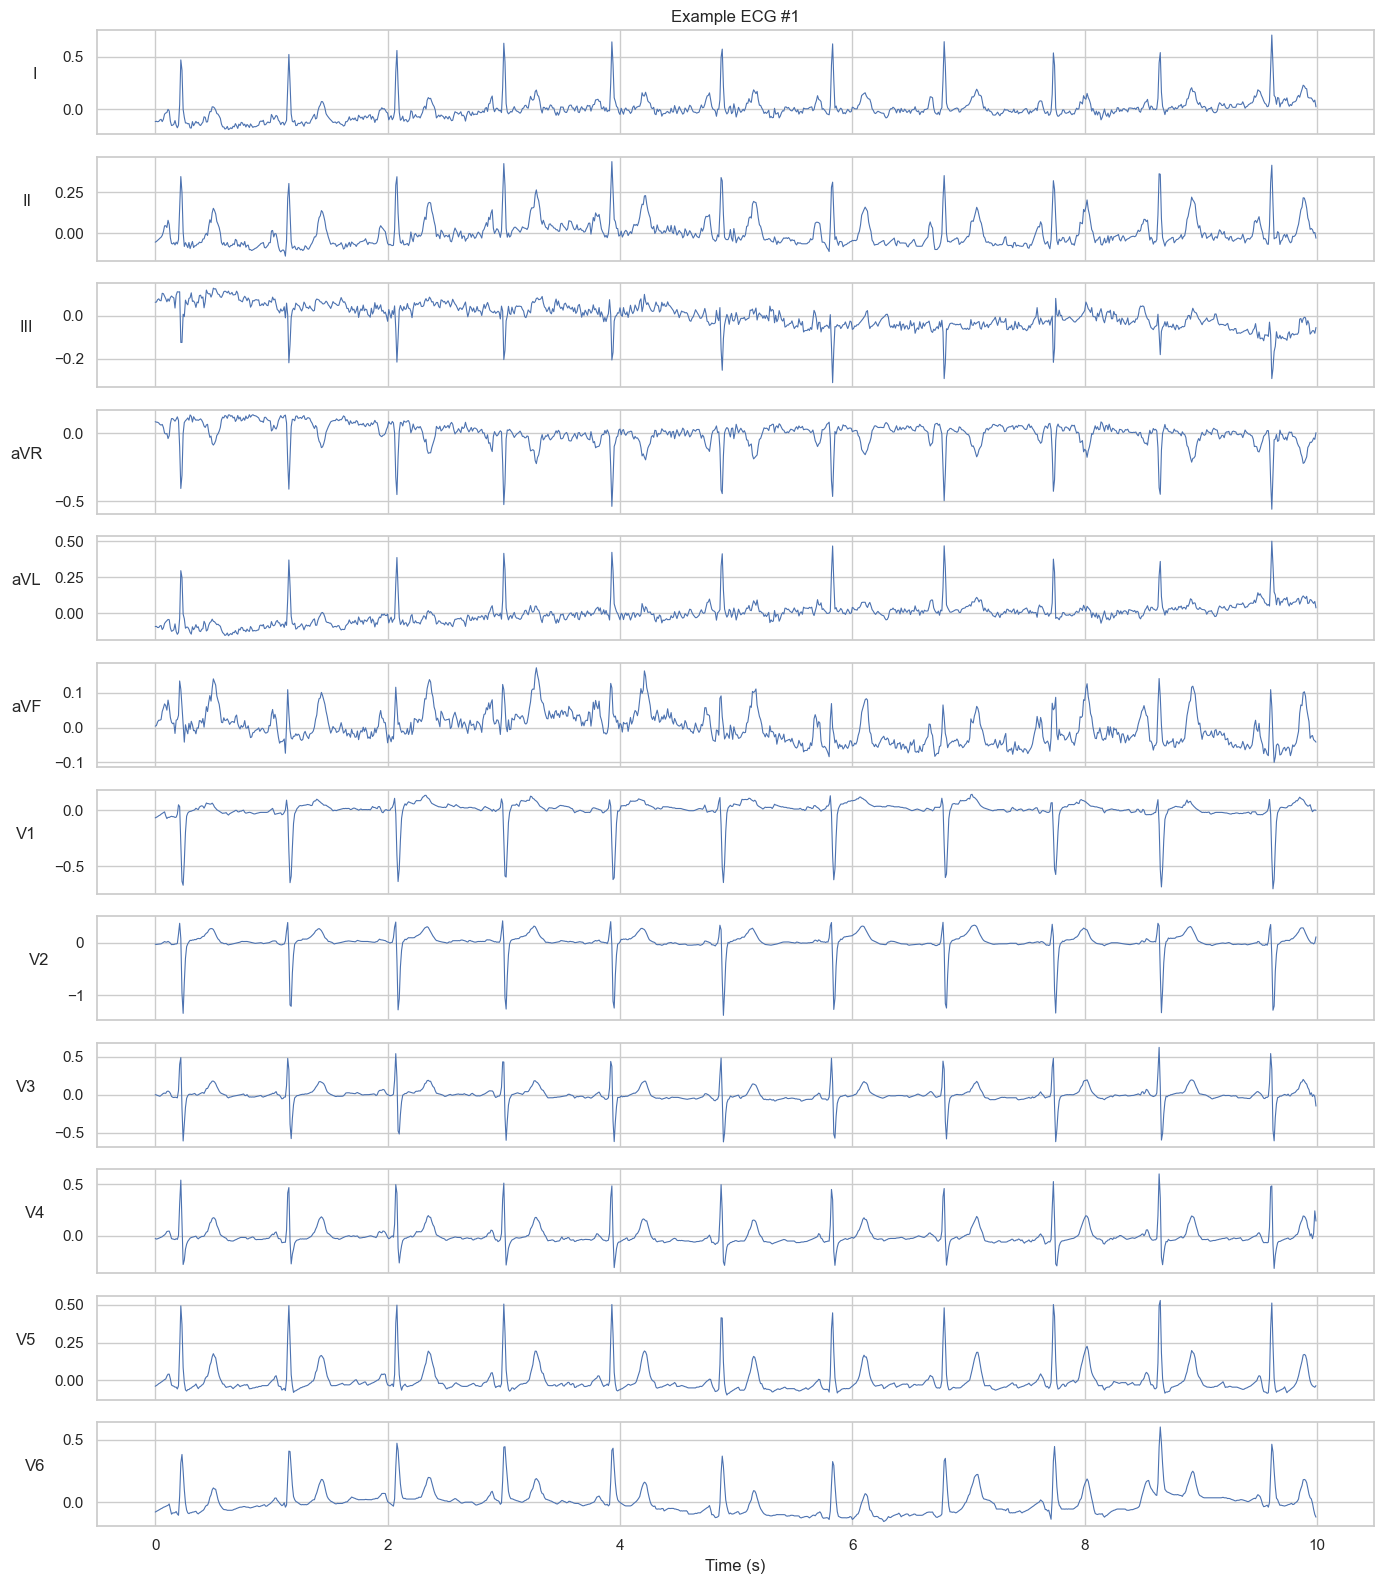

In [29]:
# visualizing a 12-lead ECG
LEAD_NAMES = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]

def plot_12_lead_ecg(signal, lead_names=LEAD_NAMES, title="12-lead ECG"):
    n_leads, n_samples = signal.shape
    time_axis = np.arange(n_samples) / SAMPLING_RATE

    fig, axes = plt.subplots(n_leads, 1, figsize=(14, 16), sharex=True)
    for i in range(n_leads):
        axes[i].plot(time_axis, signal[i], linewidth=0.8)
        axes[i].set_ylabel(lead_names[i], rotation=0, labelpad=20)
    axes[0].set_title(title)
    axes[-1].set_xlabel("Time (s)")
    plt.tight_layout()
    plt.show()

plot_12_lead_ecg(signal, title=f"Example ECG #{example_idx}")

In [31]:
# checking a few signal's shapes 
sample_ids = df.sample(5, random_state=42).index.tolist()

shapes = []
for ecg_id in sample_ids:
    rel_path = df.loc[ecg_id, signal_col]
    record_path = DATA_DIR / rel_path
    sig, _ = load_ecg_signal(record_path)
    shapes.append(sig.shape)

pd.DataFrame({"ecg_id": sample_ids, "shape": shapes})

,ecg_id,shape
0,17136,"(12, 1000)"
1,11534,"(12, 1000)"
2,17974,"(12, 1000)"
3,13825,"(12, 1000)"
4,18932,"(12, 1000)"


In [ ]:
# function to normalize ecg signals (used a lot in research)
def zscore_per_lead(signal, eps=1e-8):
    mean = signal.mean(axis=1, keepdims=True)
    std = signal.std(axis=1, keepdims=True)
    return (signal - mean) / (std + eps)

In [ ]:
# comparing stats of normalized vs original
norm_signal = zscore_per_lead(signal)

print("Raw mean/std lead 0:", signal[0].mean(), signal[0].std())
print("Norm mean/std lead 0:", norm_signal[0].mean(), norm_signal[0].std())

Raw mean/std lead 0: 0.0015080004 0.109022215
Norm mean/std lead 0: 1.373291e-07 1.0000001


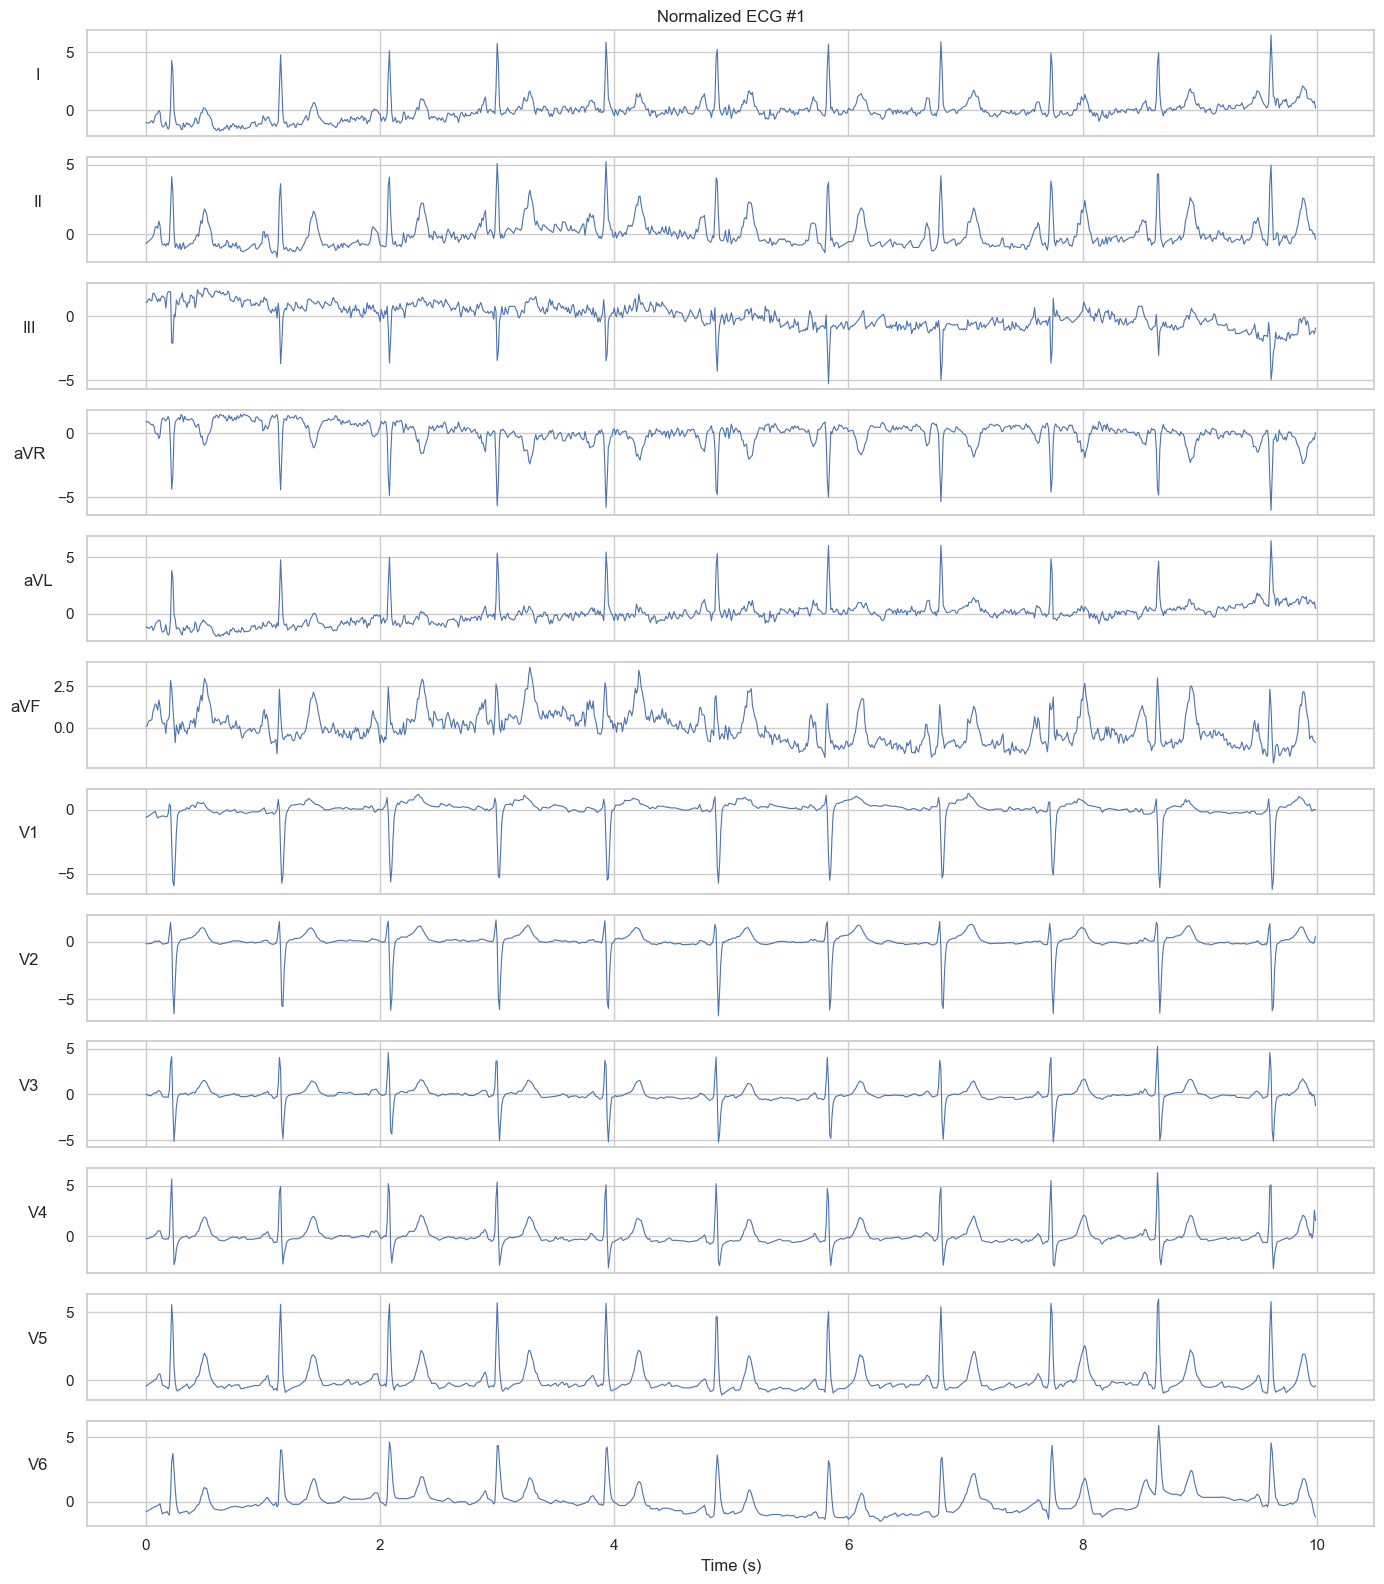

In [34]:
plot_12_lead_ecg(norm_signal, title=f"Normalized ECG #{example_idx}")

#### Sigbal quality using metadata 

In [35]:
quality_cols = ["baseline_drift", "static_noise", "burst_noise", "electrodes_problems"]
existing_quality_cols = [c for c in quality_cols if c in df.columns]

print("Existing quality columns:", existing_quality_cols)
display(df[existing_quality_cols].describe(include="all"))

Existing quality columns: ['baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems']


,baseline_drift,static_noise,burst_noise,electrodes_problems
count,1598,3260,613,30
unique,317,124,103,14
top,", V6",", I-AVR,",alles,V6
freq,221,953,140,8


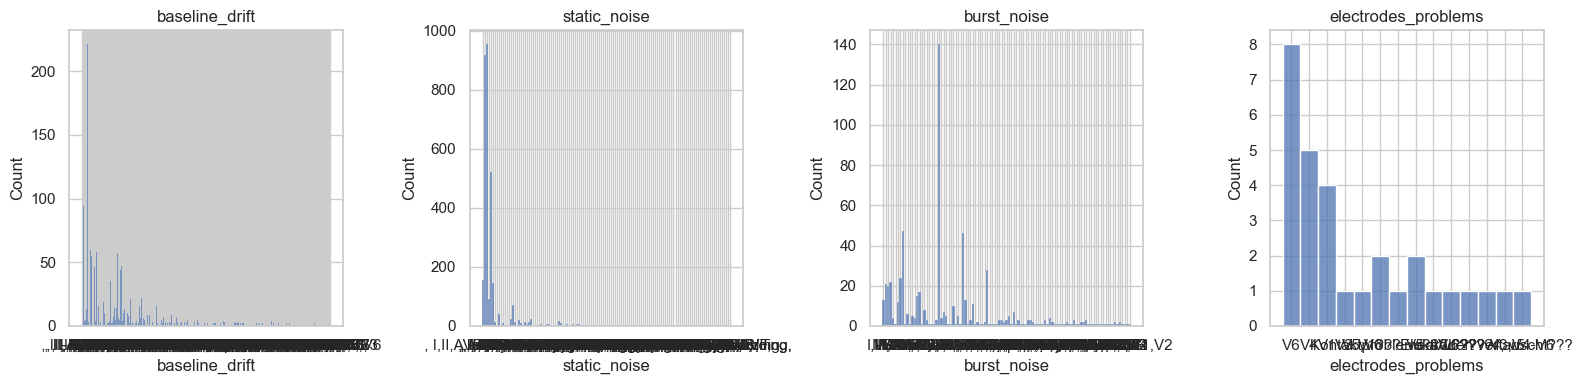

In [36]:
if existing_quality_cols:
    fig, axes = plt.subplots(1, len(existing_quality_cols), figsize=(4 * len(existing_quality_cols), 4))
    
    if len(existing_quality_cols) == 1:
        axes = [axes]
    
    for ax, col in zip(axes, existing_quality_cols):
        sns.histplot(df[col].dropna(), bins=30, ax=ax)
        ax.set_title(col)
    
    plt.tight_layout()
    plt.show()

In [38]:
def compute_simple_signal_stats(signal):
    lead_std = signal.std(axis=1)
    lead_min = signal.min(axis=1)
    lead_max = signal.max(axis=1)
    return {
        "mean_std": float(lead_std.mean()),
        "min_std": float(lead_std.min()),
        "max_std": float(lead_std.max()),
        "global_min": float(lead_min.min()),
        "global_max": float(lead_max.max()),
    }

small_ids = df.sample(20, random_state=123).index.tolist()
signal_stats = []

for ecg_id in small_ids:
    rel_path = df.loc[ecg_id, signal_col]
    record_path = DATA_DIR / rel_path
    sig, _ = load_ecg_signal(record_path)
    stats = compute_simple_signal_stats(sig)
    stats["ecg_id"] = ecg_id
    signal_stats.append(stats)

signal_stats_df = pd.DataFrame(signal_stats)
display(signal_stats_df.head())
display(signal_stats_df.describe())

,mean_std,min_std,max_std,global_min,global_max,ecg_id
0,0.182913,0.068850,0.310975,-1.182,1.774,11741
1,0.090519,0.057781,0.117602,-0.522,0.783,10899
2,0.122763,0.058244,0.207177,-1.117,0.818,15181
3,0.169254,0.083316,0.357742,-1.241,1.297,15690
4,0.190629,0.082716,0.435465,-1.600,1.607,6677


,mean_std,min_std,max_std,global_min,global_max,ecg_id
count,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000
mean,0.194166,0.078733,0.415107,-1.675200,1.745200,12328.800000
std,0.080397,0.034408,0.283180,0.649428,0.813211,4992.578193
min,0.090519,0.035794,0.117602,-2.932000,0.783000,3249.000000
25%,0.136771,0.057138,0.263505,-2.092750,1.250250,10123.000000
50%,0.181771,0.072708,0.347586,-1.507000,1.739500,11933.500000
75%,0.225088,0.086953,0.472464,-1.226250,2.035000,15308.250000
max,0.455238,0.172647,1.392256,-0.522000,4.523000,21713.000000


SR       16748
NORM      9514
ABQRS     3327
IMI       2676
ASMI      2357
LVH       2132
NDT       1825
LAFB      1623
AFIB      1514
ISC_      1272
PVC       1143
IRBBB     1118
STD_      1009
VCLVH      875
STACH      826
1AVB       793
IVCD       787
SARRH      772
NST_       767
ISCAL      659
dtype: int64

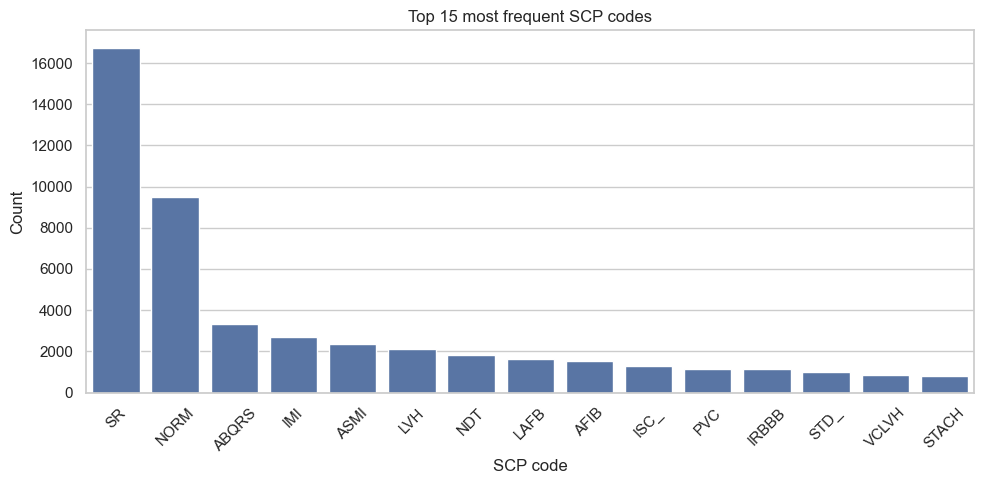

In [39]:
all_scp_codes = [code for d in df["scp_codes"] for code in d.keys()]
scp_counts = pd.Series(Counter(all_scp_codes)).sort_values(ascending=False)

display(scp_counts.head(20))

plt.figure(figsize=(10, 5))
sns.barplot(x=scp_counts.head(15).index, y=scp_counts.head(15).values)
plt.title("Top 15 most frequent SCP codes")
plt.xlabel("SCP code")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# checking superclass distribution for a potential classification problem
prevalence = (df[label_cols].mean() * 100).sort_values(ascending=False)
candidate_df = pd.DataFrame({
    "count": df[label_cols].sum().astype(int),
    "prevalence_percent": prevalence.round(2)
}).sort_values("count", ascending=False)

display(candidate_df)

,count,prevalence_percent
NORM,9514,43.64
MI,5469,25.09
STTC,5235,24.01
CD,4898,22.47
HYP,2649,12.15


In [41]:
OUTPUT_DIR = PROJECT_ROOT / "results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

clean_metadata_path = OUTPUT_DIR / "ptbxl_metadata_with_superclasses.csv"
df.to_csv(clean_metadata_path)

print("Saved to:", clean_metadata_path)

Saved to: C:\Users\Sherif\Desktop\ECG analysis\results\ptbxl_metadata_with_superclasses.csv
